<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/Gray%20wolf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Employee 1: Night
Employee 2: Morning
Employee 3: Night
Employee 4: Night
Employee 5: Morning
Employee 6: Morning
Employee 7: Night
Employee 8: Evening
Employee 9: Night
Employee 10: Night
Iteration 1: Best Fitness = 1161.80
Iteration 2: Best Fitness = 1171.80
Iteration 3: Best Fitness = 2182.80
Iteration 4: Best Fitness = 1181.80
Iteration 5: Best Fitness = 2212.80
Iteration 6: Best Fitness = 3204.80
Iteration 7: Best Fitness = 1191.80
Iteration 8: Best Fitness = 2213.80
Iteration 9: Best Fitness = 220.80
Iteration 10: Best Fitness = 200.80
Iteration 11: Best Fitness = 2192.80
Iteration 12: Best Fitness = 1211.80
Iteration 13: Best Fitness = 2202.80
Iteration 14: Best Fitness = 2232.80
Iteration 15: Best Fitness = 2242.80
Iteration 16: Best Fitness = 200.80
Iteration 17: Best Fitness = 1201.80
Iteration 18: Best Fitness = 160.80
Iteration 19: Best Fitness = 1171.80
Iteration 20: Best Fitness = 1171.80
Iteration 21: Best Fitness = 260.80
Iteration 22: Best Fitness = 1201.80
Iteration 2

,Day,Morning,Evening,Night
0,Monday,"Employee 5, Employee 2","Employee 7, Employee 6","Employee 4, Employee 3"
1,Tuesday,"Employee 5, Employee 6","Employee 3, Employee 9","Employee 4, Employee 7"
2,Wednesday,"Employee 5, Employee 6","Employee 1, Employee 8","Employee 9, Employee 10"
3,Thursday,"Employee 6, Employee 5","Employee 8, Employee 4","Employee 1, Employee 10"
4,Friday,"Employee 10, Employee 2","Employee 8, Employee 1","Employee 9, Employee 4"
5,Saturday,"Employee 3, Employee 2","Employee 8, Employee 5","Employee 10, Employee 7"
6,Sunday,"Employee 3, Employee 2","Employee 8, Employee 7","Employee 9, Employee 1"


,Employee,Weekly Shifts
0,Employee 1,4
1,Employee 2,4
2,Employee 3,4
3,Employee 4,4
4,Employee 5,5
5,Employee 6,4
6,Employee 7,4
7,Employee 8,5
8,Employee 9,4
9,Employee 10,4


Best Fitness: 120.8
Total Assignments: 42
Daily Conflicts: 0
Workload Violations: 0
All Shifts Covered: True
No Daily Conflicts: True
All Employees Have 4-5 Shifts: True


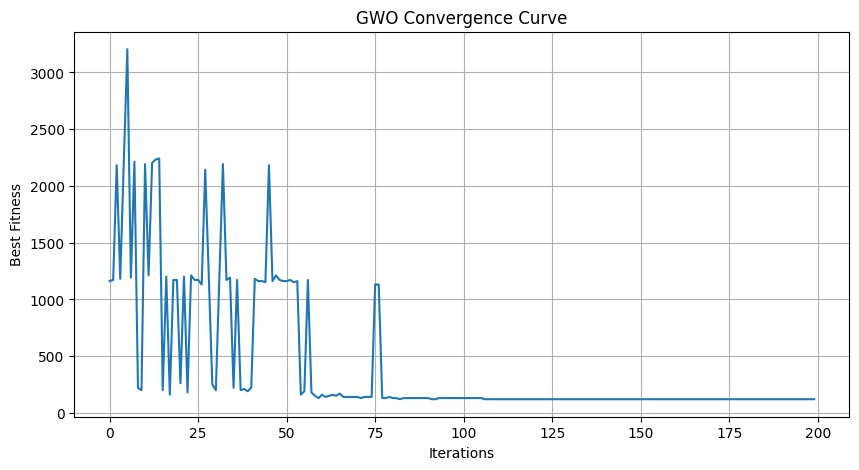

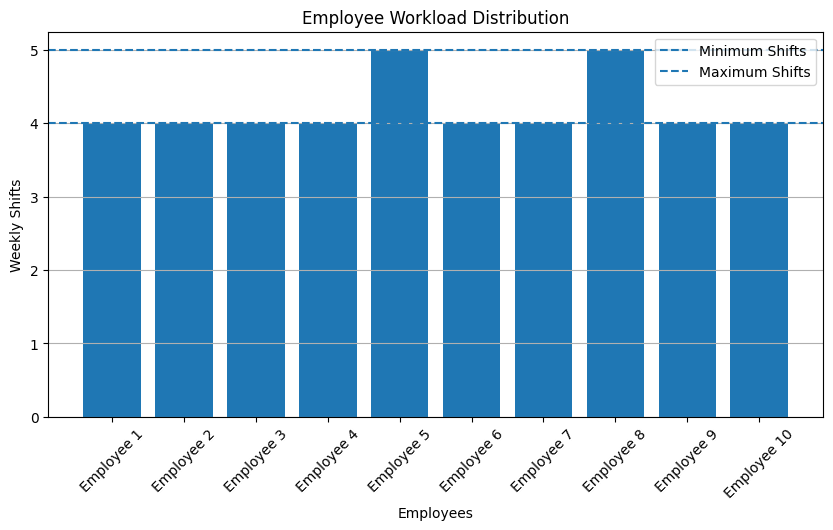

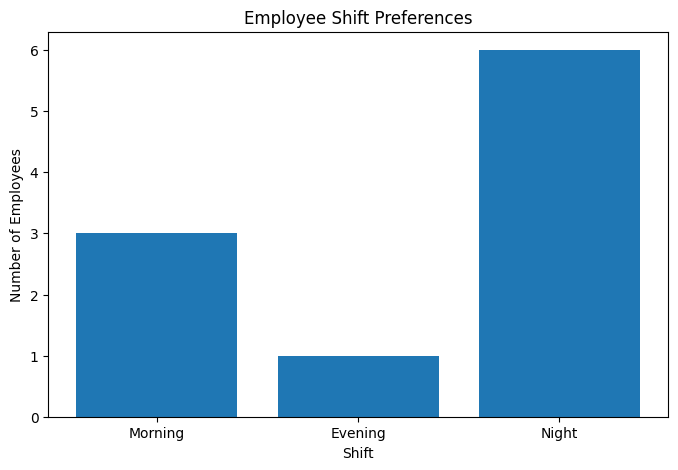

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from IPython.display import display

NUM_EMPLOYEES = 10
NUM_DAYS = 7
NUM_SHIFTS = 3
EMPLOYEES_PER_SHIFT = 2
MIN_SHIFTS = 4
MAX_SHIFTS = 5
NUM_WOLVES = 40
MAX_ITERATIONS = 200

np.random.seed(42)

days = ["Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"]

shifts = ["Morning", "Evening", "Night"]

POSITION_SHAPE = (NUM_DAYS, 6, NUM_EMPLOYEES)

employee_preferences = np.random.randint(
    0, NUM_SHIFTS, NUM_EMPLOYEES
)

for i in range(NUM_EMPLOYEES):
    print(f"Employee {i+1}: {shifts[employee_preferences[i]]}")

def decode_wolf(position):
    schedule = np.zeros((NUM_DAYS, NUM_SHIFTS, 2), dtype=int)

    for day in range(NUM_DAYS):
        cost_matrix = np.zeros((6, NUM_EMPLOYEES))

        for slot in range(6):
            shift = slot // 2
            cost_matrix[slot] = -position[day, slot]

            for emp in range(NUM_EMPLOYEES):
                if employee_preferences[emp] != shift:
                    cost_matrix[slot, emp] += 0.15

        rows, cols = linear_sum_assignment(cost_matrix)

        for row, col in zip(rows, cols):
            schedule[day, row // 2, row % 2] = col

    return schedule

def fitness_function(position):
    schedule = decode_wolf(position)
    workload = np.zeros(NUM_EMPLOYEES)
    preference_penalty = 0

    for day in range(NUM_DAYS):
        for shift in range(NUM_SHIFTS):
            for emp in schedule[day, shift]:
                workload[emp] += 1

                if employee_preferences[emp] != shift:
                    preference_penalty += 1

    workload_penalty = np.sum(
        np.maximum(MIN_SHIFTS - workload, 0) +
        np.maximum(workload - MAX_SHIFTS, 0)
    )

    fairness_penalty = np.var(workload)

    return (
        1000 * workload_penalty +
        10 * preference_penalty +
        5 * fairness_penalty
    )

wolves = np.random.rand(NUM_WOLVES, *POSITION_SHAPE)

fitness = np.array([
    fitness_function(wolf) for wolf in wolves
])

sorted_indices = np.argsort(fitness)

alpha = wolves[sorted_indices[0]].copy()
beta = wolves[sorted_indices[1]].copy()
delta = wolves[sorted_indices[2]].copy()

best_score = fitness[sorted_indices[0]]
best_history = []

for iteration in range(MAX_ITERATIONS):

    a = 2 - 2 * iteration / MAX_ITERATIONS
    new_wolves = np.zeros_like(wolves)

    for i in range(NUM_WOLVES):

        current = wolves[i].copy()

        r1 = np.random.rand(*POSITION_SHAPE)
        r2 = np.random.rand(*POSITION_SHAPE)
        A1 = 2 * a * r1 - a
        C1 = 2 * r2
        D_alpha = np.abs(C1 * alpha - current)
        X1 = alpha - A1 * D_alpha

        r1 = np.random.rand(*POSITION_SHAPE)
        r2 = np.random.rand(*POSITION_SHAPE)
        A2 = 2 * a * r1 - a
        C2 = 2 * r2
        D_beta = np.abs(C2 * beta - current)
        X2 = beta - A2 * D_beta

        r1 = np.random.rand(*POSITION_SHAPE)
        r2 = np.random.rand(*POSITION_SHAPE)
        A3 = 2 * a * r1 - a
        C3 = 2 * r2
        D_delta = np.abs(C3 * delta - current)
        X3 = delta - A3 * D_delta

        new_wolves[i] = np.clip((X1 + X2 + X3) / 3, 0, 1)

    wolves = new_wolves

    fitness = np.array([
        fitness_function(wolf) for wolf in wolves
    ])

    sorted_indices = np.argsort(fitness)

    alpha = wolves[sorted_indices[0]].copy()
    beta = wolves[sorted_indices[1]].copy()
    delta = wolves[sorted_indices[2]].copy()

    best_score = fitness[sorted_indices[0]]
    best_history.append(best_score)

    print(
        f"Iteration {iteration+1}: "
        f"Best Fitness = {best_score:.2f}"
    )

best_schedule = decode_wolf(alpha)

workload = np.zeros(NUM_EMPLOYEES, dtype=int)

for day in range(NUM_DAYS):
    for shift in range(NUM_SHIFTS):
        for emp in best_schedule[day, shift]:
            workload[emp] += 1

schedule_data = []

for day in range(NUM_DAYS):
    row = {"Day": days[day]}

    for shift in range(NUM_SHIFTS):
        row[shifts[shift]] = ", ".join(
            f"Employee {emp+1}"
            for emp in best_schedule[day, shift]
        )

    schedule_data.append(row)

schedule_df = pd.DataFrame(schedule_data)

workload_df = pd.DataFrame({
    "Employee": [f"Employee {i+1}" for i in range(NUM_EMPLOYEES)],
    "Weekly Shifts": workload
})

display(schedule_df)
display(workload_df)

daily_conflicts = 0

for day in range(NUM_DAYS):
    assigned = best_schedule[day].flatten()
    daily_conflicts += len(assigned) - len(set(assigned))

workload_violations = np.sum(
    (workload < MIN_SHIFTS) | (workload > MAX_SHIFTS)
)

print("Best Fitness:", round(best_score, 2))
print("Total Assignments:", workload.sum())
print("Daily Conflicts:", daily_conflicts)
print("Workload Violations:", workload_violations)
print("All Shifts Covered:", best_schedule.shape == (7, 3, 2))
print("No Daily Conflicts:", daily_conflicts == 0)
print("All Employees Have 4-5 Shifts:", workload_violations == 0)

plt.figure(figsize=(10, 5))
plt.plot(best_history)
plt.title("GWO Convergence Curve")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(workload_df["Employee"], workload_df["Weekly Shifts"])
plt.axhline(MIN_SHIFTS, linestyle="--", label="Minimum Shifts")
plt.axhline(MAX_SHIFTS, linestyle="--", label="Maximum Shifts")
plt.title("Employee Workload Distribution")
plt.xlabel("Employees")
plt.ylabel("Weekly Shifts")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y")
plt.show()

plt.figure(figsize=(8, 5))
preference_counts = [
    np.sum(employee_preferences == i)
    for i in range(NUM_SHIFTS)
]
plt.bar(shifts, preference_counts)
plt.title("Employee Shift Preferences")
plt.xlabel("Shift")
plt.ylabel("Number of Employees")
plt.show()

with pd.ExcelWriter("GWO_Employee_Scheduling.xlsx") as writer:
    schedule_df.to_excel(writer, sheet_name="Weekly Schedule", index=False)
    workload_df.to_excel(writer, sheet_name="Workload", index=False)

    pd.DataFrame({
        "Iteration": range(1, MAX_ITERATIONS + 1),
        "Best Fitness": best_history
    }).to_excel(writer, sheet_name="Convergence", index=False)

    pd.DataFrame({
        "Employee": [f"Employee {i+1}" for i in range(NUM_EMPLOYEES)],
        "Preferred Shift": [
            shifts[p] for p in employee_preferences
        ]
    }).to_excel(writer, sheet_name="Preferences", index=False)

from google.colab import files
files.download("GWO_Employee_Scheduling.xlsx")
